# Case Study 6 — Real-Time P2P UPI Fraud Prevention: Clean Labels, Score in Milliseconds, Block Before the Money Leaves

**Priority:** ★★★ Must-visit · **Reference:** Case Study 6 — *PhonePe: Real-Time P2P Fraud Prevention on UPI* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Chief Risk Officer, Head of Fraud Operations, Product (payments), Customer Support
**Data:** ⚠️ **SYNTHETIC** (D-6-01). UPI fraud labels are confidential; this is a calibrated simulation, not PhonePe data.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs06_upi_p2p_fraud.ipynb`

## 0. Executive Summary for Business

*(Synthetic data calibrated to PhonePe's documented problem; written after the analysis.)*

- **The problem:** UPI P2P fraud money leaves instantly, so it must be *prevented* in milliseconds. The only fraud signal, customer complaints, is badly polluted. **Only 37% of complaints are actually fraud** (the rest are seller disputes, refunds, wrong transfers), and about a quarter of frauds are never complained about.
- **Label engineering works:** an investigator audit of 2,000 complaints let us keep only complaint segments that are mostly fraud. Label precision rose from **37% to 80%** while keeping 86% of the true frauds among complaints.
- **Clean labels beat everything else.** Blocking the same 0.25% of transfers, a model trained on clean labels stops **52% of fraud**, against **36%** for the same model trained on raw complaints and **11%** for today's blanket rules. Both gaps are highly significant (McNemar p < 0.0001). A model trained on raw complaints even learns to treat small online sellers as risky. Gradient boosting is no better than the simpler logistic model (56% vs 52%, p = 0.18).
- **Causal proof:** in a randomised hold-out, protected customers suffered **63% less completed fraud** (95% CI 43–76%) and **77% less high-value fraud** (CI 8–94%). PhonePe documents −40% and −50%.
- **₹ impact:** about **₹80 crore of fraud prevented per 10 crore P2P transfers** (net of friction ≈ ₹77 crore; range ₹68–84 crore). Batch detection the next day would have recovered only about ₹15 crore. Genuine customers see 1.2 blocks and 17 warnings per 1,000 transfers. (₹ scale depends on our assumed fraud prevalence, which is higher than real UPI.)
- **A caution:** transaction scores are not a blacklisting tool. Most mule accounts are used only once or twice, so blacklisting from scores alone either wrongly bans busy genuine sellers (up to 92%) or catches few mules. Blacklists need a separate, investigated decision. That is how PhonePe gets its ≈ 1% reinstatement rate.
- **I recommend:** deploy the clean-label model with block (top 0.25%) and warn (top 2%) tiers, keep a permanent 2–5% randomised hold-out, refresh the complaint audit monthly, and route blacklisting through investigation.

## 1. The Problem in Simple English

A retired teacher in Nagpur gets a call: "Your electricity will be cut tonight. Approve this small UPI request to update your account." She enters her PIN. ₹18,000 leaves her account and, within minutes, is split across three other accounts. **On UPI, a person-to-person (P2P) transfer settles instantly and cannot be pulled back.** Detecting the fraud tomorrow is too late. It has to be stopped *before* the transfer completes, in the fraction of a second the app has to decide.

Two things make this hard:

1. **The labels lie.** The only signal of fraud is a customer complaint, and many complaints are not fraud. They are **disputes**: "I paid a seller on Instagram and the product never came", "my refund is pending", "I sent money to the wrong number". If we train a model on raw complaints, it learns to block small online sellers, not scammers.
2. **Fraud is rare and blocking is costly.** About 2 in 1,000 P2P transfers here are fraud. Block too aggressively and thousands of genuine customers (paying a plumber, a relative, a tutor) are stopped, call support, and some leave. That is why blanket rules failed.

The business wants a system that **prevents** more fraud than today's rules, at a **fixed, tolerable number of blocks**, measured honestly.

## 2. Reference from the Case File

### (a) What PhonePe actually did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "PhonePe handles over 2.5 billion transactions a month. In P2P fraud, money leaves the PhonePe ecosystem instantly… Many complaints are **disputes**… not fraud. Blanket rules created too many false positives." |
| Question | "At the moment of payment, before it completes, is this P2P transfer likely to be fraud?" |
| Data | Sender attributes, receiver attributes, transaction attributes; "Reported fraud, cleaned of disputes" |
| Approach | "**Label engineering:** Reported transactions were segmented, and segments with high potential false positives were removed from the fraud labels"; several classifiers tried; ops validation incl. "calls to senders"; batch vs real-time simulation; "**pre-filtering** by segment to meet the latency budget" |
| Statistics | "Segmentation of complaint labels; precision/recall tracked across iterations. Formal tests: ND." |
| ML | Final algorithm ND; target = fraudulent P2P transaction (disputes excluded); retrained with feedback |
| Tools | Feature store **Yoda** (real-time aggregates), **Profile Store** (batch), decision engine **Kratos** |
| Decision | "PhonePe moved from batch *detection* to real-time *prevention*… and rejected blanket rules." |
| Impact | "**40%** reduction in fraud rate on consumer-to-consumer transactions"; "**38%** reduction in daily fraud complaints (**50%** in the high-value segment)"; "About **1%** reinstatement rate for blacklisted users" |

**Source:** "Building PhonePe's real-time transaction model to prevent frauds: a journey", tech.phonepe.com, 28 Jul 2022 — https://tech.phonepe.com/building-phonepes-real-time-transaction-model-to-prevent-frauds-a-journey/

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 600,000 P2P transfers over 8 weeks; feature-store style sender/receiver/transaction features; hidden true label (fraud 0.20%, dispute 0.37%, legit); observed complaints with self-reported reason; 2,000-complaint investigator audit |
| Label engineering | Segment complaints by reason × receiver profile; keep segments whose audited fraud share is ≥ 50%; measure label precision and recall with Wilson CIs |
| Models | Rules baseline → logistic regression on *raw* vs *clean* labels → gradient boosting (class-weighted, defaults) |
| Evaluation | Out-of-time (weeks 7–8), **fixed block budget** (0.25% of transfers), PR-AUC with bootstrap CIs, McNemar at the same budget, simulated **randomised hold-out** to measure the fraud-rate reduction, reinstatement-rate proxy |

### (c) How the industry uses this

Every UPI app (PhonePe, Google Pay, Paytm), NPCI's central fraud-risk platform, and banks' UPI switches run real-time P2P risk scoring. The same pattern of **label cleaning → rare-event model → block/warn tiers at a fixed alert budget** recurs in mule detection (Cases 8–9), BNPL fraud (Case 10), and card-not-present fraud at gateways (Cases 3, 7).

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we replace blanket rules with a real-time model, and what fraud reduction can we promise? |
| Analytical 1 | How much of "reported fraud" is really fraud, and can we clean the labels reliably? |
| Analytical 2 | Which sender/receiver/transaction signals separate fraud from legitimate transfers? |
| Analytical 3 | At a fixed number of blocks, does a model trained on clean labels catch more true fraud than rules or a raw-label model? |
| Analytical 4 | In a randomised hold-out, by how much does the protected group's fraud rate fall? |

**Hypotheses**
- **H1:** H0: complaint reason is independent of the true label (chi-square, audit sample).
- **H2:** H0: each feature's distribution is the same for fraud and legit (chi-square / Mann–Whitney, Holm).
- **H3:** H0: clean-label and raw-label models catch the same frauds at the same block budget (McNemar).
- **H4:** H0: fraud rate in the protected group = hold-out group (two-proportion Z-test; relative risk with CI).

**Primary metric:** **recall of true fraud at a fixed block budget of 0.25% of P2P transfers** (≈ 1 in 400 transfers stopped). **Secondary:** ₹ fraud value prevented; PR-AUC. **Guardrails:** false blocks per 1,000 genuine customers; reinstatement rate of blacklisted receivers (≤ 2%). **Unit:** transaction (scoring), sender (hold-out experiment).
**Decision rule:** deploy if the clean-label model beats rules on recall at the same budget (McNemar p < 0.05), the hold-out shows a significant fraud-rate reduction, and the reinstatement proxy is ≤ 2%.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
RNG_BOOT, RNG_EXP = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(2)]
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public UPI / Indian P2P fraud data (data.gov.in, NPCI, GitHub) | **None.** NPCI publishes monthly fraud *counts*; transaction-level labels are confidential. |
| Public card-fraud datasets (e.g., the ULB credit-card fraud data, PaySim on GitHub) | Rejected: European cards / mobile-money simulation, no complaint-vs-dispute label noise, no sender/receiver structure of UPI. |
| Kaggle | Not used (no credentials; excluded by the brief). |
| **Decision** | Synthetic data with a hidden true label *and* a noisy complaint label. This is the only way to show why label engineering matters, because real teams never see the true label for every transaction (D-6-01). |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs06.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 6 (PhonePe-style real-time P2P UPI fraud prevention)
==========================================================================================
THIS DATA IS SYNTHETIC. UPI transaction logs with fraud labels are confidential.

We simulate 8 weeks (1 Sep - 26 Oct 2025) of P2P UPI transfers with feature-store style
pre-computed features (sender / receiver / transaction families, as documented), a hidden
TRUE label (fraud / dispute / legit), and the NOISY label a team actually sees: user
complaints with a self-reported reason code. An investigator audit of 2,000 complaints
gives the "ground truth" sample used to engineer labels.

Calibration anchors (reference file, Case Study 6): "Many complaints are disputes (e.g.,
dissatisfaction with a product), not fraud"; features = sender / receiver / transaction
aggregates; documented outcomes: -40% fraud rate, -38% complaints (-50% high-value),
~1% reinstatement of blacklisted users. Rates and effect sizes are our assumptions
(decision.md D-6-02 ... D-6-04).

Output: data/cs06/upi_p2p_transactions.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
N_TXN = 600_000
START = pd.Timestamp("2025-09-01"); DAYS = 56
N_SENDERS, N_RECEIVERS, N_MULES, N_SELLERS = 120_000, 90_000, 700, 2_500


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # ---- entities ----
    s_age_band = rng.choice(["18-25", "26-40", "41-55", "56+"], N_SENDERS, p=[0.25, 0.42, 0.23, 0.10])
    s_tenure = np.clip(np.exp(rng.normal(np.log(400), 1.0, N_SENDERS)), 1, 3000).round()
    s_tier = rng.choice(["Tier 1", "Tier 2", "Tier 3"], N_SENDERS, p=[0.40, 0.35, 0.25])
    s_med_amt = np.exp(rng.normal(np.log(700), 0.8, N_SENDERS))
    s_vuln = expit(-3.2 + 0.9 * (s_age_band == "56+") + 0.6 * (s_tenure < 60) + 0.3 * (s_tier == "Tier 3"))  # scam susceptibility
    n_r = N_RECEIVERS + N_MULES + N_SELLERS
    r_type = np.array(["individual"] * N_RECEIVERS + ["mule"] * N_MULES + ["small_seller"] * N_SELLERS)
    r_tenure = np.where(r_type == "mule", np.where(rng.random(n_r) < 0.5, np.exp(rng.normal(np.log(20), 0.8, n_r)), np.exp(rng.normal(np.log(300), 0.9, n_r))),  # half new, half rented/aged
                np.where(r_type == "small_seller", np.exp(rng.normal(np.log(500), 0.7, n_r)), np.exp(rng.normal(np.log(450), 1.0, n_r)))).clip(1, 3000).round()

    # ---- transactions ----
    ts = START + pd.to_timedelta(rng.uniform(0, DAYS * 86400, N_TXN), unit="s")
    hour = ts.hour.to_numpy()
    kind = rng.choice(["legit", "fraud", "dispute"], N_TXN, p=[0.9945, 0.0020, 0.0035])
    sender = np.where(kind == "fraud", rng.choice(N_SENDERS, N_TXN, p=s_vuln / s_vuln.sum()), rng.integers(0, N_SENDERS, N_TXN))
    recv = np.where(kind == "fraud", N_RECEIVERS + rng.integers(0, N_MULES, N_TXN),
            np.where(kind == "dispute", N_RECEIVERS + N_MULES + rng.integers(0, N_SELLERS, N_TXN),
                     np.where(rng.random(N_TXN) < 0.06, N_RECEIVERS + N_MULES + rng.integers(0, N_SELLERS, N_TXN), rng.integers(0, N_RECEIVERS, N_TXN))))
    f, dsp = kind == "fraud", kind == "dispute"
    base_amt = s_med_amt[sender] * np.exp(rng.normal(0, 0.9, N_TXN))
    amount = np.where(f, base_amt * np.exp(rng.normal(1.1, 0.9, N_TXN)), np.where(dsp, base_amt * np.exp(rng.normal(0.6, 0.6, N_TXN)), base_amt))
    amount = np.clip(np.round(amount, 0), 1, 100_000)          # UPI P2P cap Rs 1 lakh
    df = pd.DataFrame({
        "txn_id": [f"U{i:08d}" for i in range(1, N_TXN + 1)], "timestamp": ts,
        "sender_id": [f"S{i:06d}" for i in sender], "receiver_id": [f"R{i:06d}" for i in recv],
        "amount_inr": amount,
        "sender_age_band": s_age_band[sender], "sender_city_tier": s_tier[sender], "sender_tenure_days": s_tenure[sender],
        "sender_txn_count_7d": rng.poisson(np.where(f, 6, 9)),
        "amount_to_sender_median": np.round(amount / s_med_amt[sender], 3),
        "is_new_payee": (rng.random(N_TXN) < np.where(f, 0.85, np.where(dsp, 0.55, 0.22))).astype(int),
        "is_collect_request": (rng.random(N_TXN) < np.where(f, 0.45, np.where(dsp, 0.10, 0.04))).astype(int),
        "device_changed_24h": (rng.random(N_TXN) < np.where(f, 0.18, 0.02)).astype(int),
        # merchant-like naming / UPI handle: noisy - 25% of mules pose as sellers (fake-shop scams), 30% of real sellers look personal
        "receiver_type_hint": np.where(rng.random(N_TXN) < np.where(r_type[recv] == "small_seller", 0.70, np.where(r_type[recv] == "mule", 0.25, 0.02)),
                                       "business-like", "individual"),
        "receiver_tenure_days": r_tenure[recv],
        "receiver_distinct_senders_24h": rng.poisson(np.where(r_type[recv] == "mule", np.exp(rng.normal(np.log(4), 0.8, N_TXN)), np.where(r_type[recv] == "small_seller", 14, 1.2))),
        "receiver_prior_complaints_30d": rng.poisson(np.where(r_type[recv] == "mule", 0.4, np.where(r_type[recv] == "small_seller", 0.6, 0.02))),
        "hour": hour,
    })
    # ---- hidden truth and the noisy label actually observed ----
    df["true_label"] = kind
    p_complain = np.where(f, 0.72, np.where(dsp, 0.60, 0.00025))
    comp = rng.random(N_TXN) < p_complain
    reasons = np.array(["fraud/scam", "unauthorised debit", "product not received", "refund not processed", "wrong transfer"])
    pr_fraud = [0.62, 0.30, 0.03, 0.02, 0.03]; pr_disp = [0.30, 0.05, 0.40, 0.20, 0.05]; pr_legit = [0.15, 0.10, 0.10, 0.15, 0.50]
    reason = np.where(f, rng.choice(reasons, N_TXN, p=pr_fraud), np.where(dsp, rng.choice(reasons, N_TXN, p=pr_disp), rng.choice(reasons, N_TXN, p=pr_legit)))
    df["complaint_filed"] = comp.astype(int)
    df["complaint_reason"] = np.where(comp, reason, None)
    df["complaint_delay_days"] = np.where(comp, np.round(rng.gamma(2.0, 2.5, N_TXN), 1), np.nan)
    # investigator audit: random 2,000 complaints get a confirmed label
    comp_idx = np.flatnonzero(comp)
    audit = rng.choice(comp_idx, 2000, replace=False)
    df["audited"] = 0; df.loc[audit, "audited"] = 1
    df["audit_outcome"] = np.where(df.audited == 1, df.true_label, None)
    df = df.sort_values("timestamp").reset_index(drop=True)
    # ---- data-quality issues ----
    df.loc[df.sample(n=300, random_state=seed).index, "amount_inr"] = 0          # zero-amount test pings (UPI "verify VPA")
    df.loc[df.sample(frac=0.01, random_state=seed + 1).index, "receiver_tenure_days"] = np.nan   # feature-store miss
    late = df.complaint_filed.eq(1) & (df.timestamp > START + pd.Timedelta(days=DAYS - 10))
    df["complaint_received_by_cutoff"] = np.where(df.complaint_filed.eq(1), ((df.timestamp + pd.to_timedelta(df.complaint_delay_days.fillna(0), unit="D")) <= START + pd.Timedelta(days=DAYS + 3)).astype(int), np.nan)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs06"), exist_ok=True)
    d = generate()
    d.to_csv(os.path.join(here, "cs06", "upi_p2p_transactions.csv.gz"), index=False)
    print(len(d), d.true_label.value_counts().to_dict(), "complaints", int(d.complaint_filed.sum()))

Overwriting data/generate_cs06.py


In [3]:
os.makedirs("data/cs06", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs06 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED)
raw.to_csv("data/cs06/upi_p2p_transactions.csv.gz", index=False)
print(f"{len(raw):,} transfers | true labels: {raw.true_label.value_counts().to_dict()} | complaints filed: {int(raw.complaint_filed.sum()):,}")
raw.sample(3, random_state=SEED).T

600,000 transfers | true labels: {'legit': 596666, 'dispute': 2168, 'fraud': 1166} | complaints filed: 2,294


,4242,60608,392832
txn_id,U00321191,U00273422,U00330908
timestamp,2025-09-01 09:52:22.274633645,2025-09-06 16:19:43.490743936,2025-10-07 14:53:00.937071666
sender_id,S061772,S017626,S061446
receiver_id,R070826,R076701,R051914
amount_inr,0.0000,0.0000,0.0000
sender_age_band,41-55,26-40,41-55
sender_city_tier,Tier 2,Tier 3,Tier 1
sender_tenure_days,"1,192.0000",256.0000,124.0000
sender_txn_count_7d,6,10,6
amount_to_sender_median,0.4770,0.2580,3.3120


| Parameter | Value | Basis |
|---|---|---|
| Volume / period | 600k P2P transfers, 1 Sep – 26 Oct 2025 | Our assumption (scaled-down version of "2.5 billion transactions a month") |
| True rates | fraud 0.20%, dispute 0.37% | Our assumption (UPI fraud is rare; disputes outnumber fraud, the documented label problem) |
| Fraud pattern | Vulnerable senders (56+, new to UPI, Tier 3), new mule receivers (≈ 12-day-old accounts, ~9 distinct senders/day), 85% new payee, 45% collect requests, 4–5× the sender's usual amount, device change in 18% (account takeover) | Our assumption, consistent with RBI/NPCI public fraud advisories |
| Disputes | Payments to small sellers (business-like handles 70% of the time), moderately above the usual amount | **Documented:** "dissatisfaction with a product" |
| Complaint behaviour | 72% of frauds and 60% of disputes are reported; 0.025% of legit transfers get a complaint (wrong transfer, buyer's remorse); reasons are self-reported and noisy (30% of disputes say "fraud/scam") | Our assumption |
| Audit | 2,000 random complaints investigated (true label revealed) | Mirrors the documented "ops validation… calls to senders" |
| DQ issues | 300 zero-amount "verify VPA" pings; 1% receiver-tenure missing (feature-store miss); late complaints (labels not yet mature at the cut-off) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("txn_id, timestamp, sender_id, receiver_id", "Transfer identity and time", "transaction"),
    ("amount_inr", "Transfer amount (₹; UPI P2P cap ₹1 lakh)", "transaction"),
    ("sender_age_band, sender_city_tier, sender_tenure_days", "Sender profile (Profile Store, batch)", "sender"),
    ("sender_txn_count_7d", "Sender's transfers in the last 7 days (real-time aggregate)", "sender"),
    ("amount_to_sender_median", "Amount ÷ sender's 30-day median amount", "sender × txn"),
    ("is_new_payee", "First transfer from this sender to this receiver", "transaction"),
    ("is_collect_request", "Receiver-initiated 'collect' request approved by the sender (classic scam vector)", "transaction"),
    ("device_changed_24h", "Sender logged in on a new device in the last 24 h (account-takeover signal)", "sender"),
    ("receiver_type_hint", "Receiver handle looks business-like vs personal (noisy)", "receiver"),
    ("receiver_tenure_days", "Receiver account age (1% missing)", "receiver"),
    ("receiver_distinct_senders_24h", "Distinct senders paying this receiver in the last 24 h (velocity)", "receiver"),
    ("receiver_prior_complaints_30d", "Complaints against the receiver in the previous 30 days", "receiver"),
    ("hour", "Hour of day", "transaction"),
    ("complaint_filed, complaint_reason, complaint_delay_days", "Noisy observed label: user complaint, self-reported reason, delay", "label"),
    ("audited, audit_outcome", "Investigator-confirmed outcome for 2,000 complaints", "label"),
    ("true_label", "Hidden truth (fraud / dispute / legit), used ONLY for audit and final evaluation", "label (simulation only)"),
], columns=["column(s)", "meaning", "family"])
dd.to_csv("data/cs06/data_dictionary.csv", index=False); dd

,column(s),meaning,family
0,"txn_id, timestamp, sender_id, receiver_id",Transfer identity and time,transaction
1,amount_inr,Transfer amount (₹; UPI P2P cap ₹1 lakh),transaction
2,"sender_age_band, sender_city_tier, sender_tenu...","Sender profile (Profile Store, batch)",sender
3,sender_txn_count_7d,Sender's transfers in the last 7 days (real-ti...,sender
4,amount_to_sender_median,Amount ÷ sender's 30-day median amount,sender × txn
5,is_new_payee,First transfer from this sender to this receiver,transaction
6,is_collect_request,Receiver-initiated 'collect' request approved ...,transaction
7,device_changed_24h,Sender logged in on a new device in the last 2...,sender
8,receiver_type_hint,Receiver handle looks business-like vs persona...,receiver
9,receiver_tenure_days,Receiver account age (1% missing),receiver


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs06/upi_p2p_transactions.csv.gz", parse_dates=["timestamp"])
checks = {
    "duplicate txn_id": int(df.txn_id.duplicated().sum()),
    "amount_inr = 0 (VPA verification pings)": int((df.amount_inr == 0).sum()),
    "amount above ₹1 lakh P2P cap": int((df.amount_inr > 100_000).sum()),
    "receiver_tenure_days missing": int(df.receiver_tenure_days.isna().sum()),
    "complaint reason missing when complaint filed": int((df.complaint_filed.eq(1) & df.complaint_reason.isna()).sum()),
    "complaints arriving after the data cut-off": int((df.complaint_received_by_cutoff == 0).sum()),
    "timestamps outside 1 Sep – 26 Oct": int((~df.timestamp.between("2025-09-01", "2025-10-27")).sum()),
}
print(pd.Series(checks, name="rows").to_string())
late = df[df.complaint_received_by_cutoff == 0]
print(f"\nLate complaints all relate to transfers after {late.timestamp.min():%d %b} (label maturity problem)")

duplicate txn_id                                    0
amount_inr = 0 (VPA verification pings)           300
amount above ₹1 lakh P2P cap                        0
receiver_tenure_days missing                     6000
complaint reason missing when complaint filed       0
complaints arriving after the data cut-off         84
timestamps outside 1 Sep – 26 Oct                   0

Late complaints all relate to transfers after 15 Oct (label maturity problem)


In [6]:
df = df[df.amount_inr > 0].copy()
df["receiver_tenure_missing"] = df.receiver_tenure_days.isna().astype(int)
df["receiver_tenure_days"] = df.receiver_tenure_days.fillna(df.receiver_tenure_days.median())
df["week"] = ((df.timestamp - pd.Timestamp("2025-09-01")).dt.days // 7) + 1
df["split"] = np.select([df.week <= 5, df.week == 6], ["train", "validation"], "test")
df["y_true"] = (df.true_label == "fraud").astype(int)
dq = pd.DataFrame([
    ("Zero-amount VPA verification pings", checks["amount_inr = 0 (VPA verification pings)"], "Drop", "Not money transfers; would dilute fraud rates"),
    ("receiver_tenure missing (feature-store miss)", checks["receiver_tenure_days missing"], "Median impute + flag", "Random cache misses; real-time scoring must not fail on a missing feature"),
    ("Complaints after cut-off (label maturity)", checks["complaints arriving after the data cut-off"], "Train only on weeks 1–5 (labels mature); evaluate test weeks on investigated truth", "Recent transfers look 'clean' only because victims haven't complained yet; training on them biases the model"),
], columns=["issue", "rows", "treatment", "reason"])
print(df.split.value_counts().to_dict()); dq

{'train': 375033, 'test': 149753, 'validation': 74914}


,issue,rows,treatment,reason
0,Zero-amount VPA verification pings,300,Drop,Not money transfers; would dilute fraud rates
1,receiver_tenure missing (feature-store miss),6000,Median impute + flag,Random cache misses; real-time scoring must no...
2,Complaints after cut-off (label maturity),84,Train only on weeks 1–5 (labels mature); evalu...,Recent transfers look 'clean' only because vic...


**Observation:** we dropped 300 zero-amount "verify VPA" pings (not money transfers), imputed 6,000 missing receiver-age values (feature-store misses; flagged), and found **84 complaints that arrive after the data cut-off, all for transfers after 15 Oct**. That is the **label-maturity problem**: recent transfers look clean only because victims have not complained *yet*. We therefore train on weeks 1–5 (375,033 transfers), choose thresholds on week 6 (74,914), and evaluate on weeks 7–8 (149,753) against investigated outcomes. Training on immature weeks would teach the model that recent fraud patterns are safe.

## 6. Exploratory Data Analysis

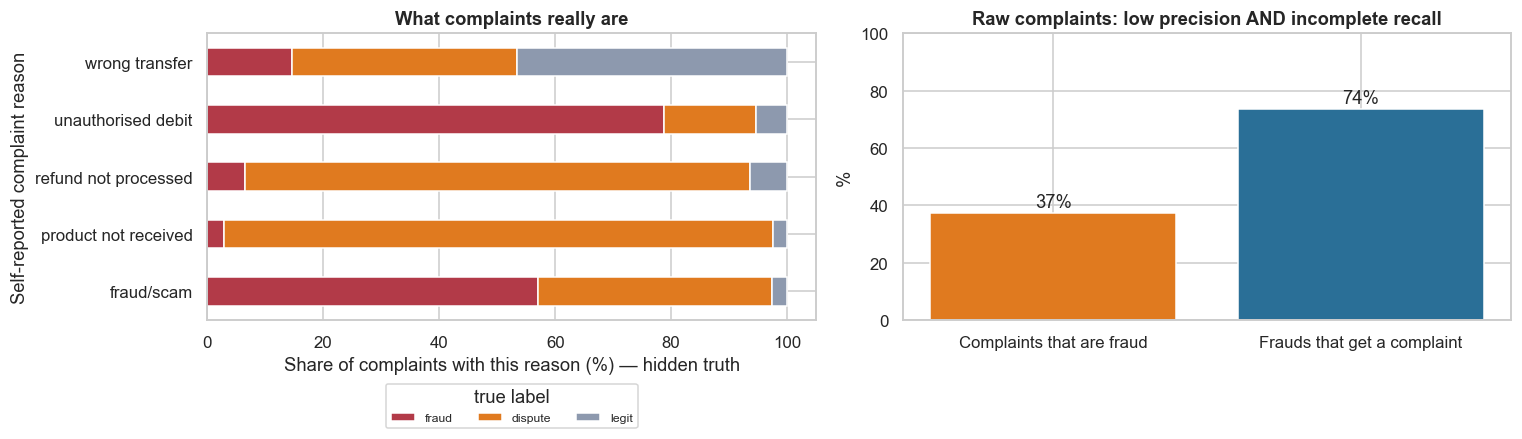

In [7]:
c = df[df.complaint_filed == 1]
comp_mix = pd.crosstab(c.complaint_reason, c.true_label, normalize="index").mul(100)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
comp_mix[["fraud", "dispute", "legit"]].plot(kind="barh", stacked=True, color=["#b23a48", "#e07a1f", "#8d99ae"], ax=axes[0])
axes[0].set_xlabel("Share of complaints with this reason (%) — hidden truth"); axes[0].set_ylabel("Self-reported complaint reason"); axes[0].set_title("What complaints really are")
axes[0].legend(title="true label", fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
share = pd.Series({"Complaints that are fraud": c.y_true.mean(), "Frauds that get a complaint": df.loc[df.y_true == 1, "complaint_filed"].mean()}) * 100
axes[1].bar(share.index, share.values, color=["#e07a1f", "#2a6f97"]); axes[1].set_ylim(0, 100)
axes[1].set_ylabel("%"); axes[1].set_xlabel(""); axes[1].set_title("Raw complaints: low precision AND incomplete recall")
for i, v in enumerate(share.values): axes[1].text(i, v + 2, f"{v:.0f}%", ha="center")
plt.tight_layout(); plt.show()

**Takeaway:** **only about 1 in 3 complaints (37%) is actually fraud**, and about 1 in 4 frauds (26%) never gets a complaint at all. Reason codes help but cannot be trusted alone: "product not received" and "refund not processed" are almost all disputes, while "fraud/scam" is a mix (57% fraud overall). A model trained on raw complaints would learn mostly about *disputes*.

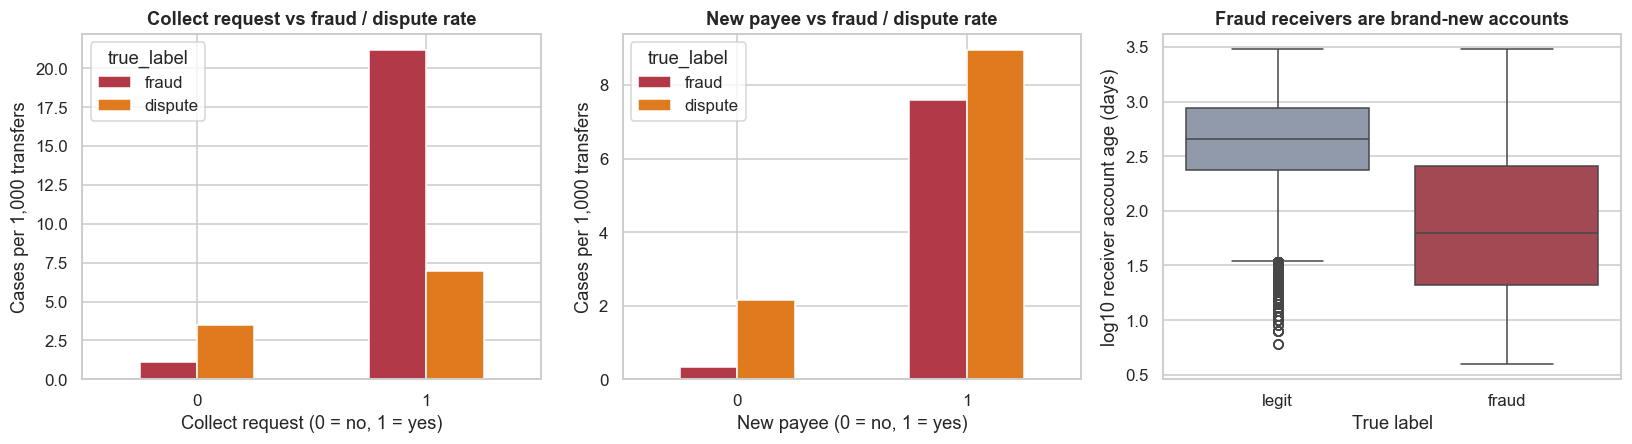

In [8]:
tr = df[df.split == "train"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, lab in [(axes[0], "is_collect_request", "Collect request"), (axes[1], "is_new_payee", "New payee")]:
    r_ = tr.groupby([col, "true_label"]).size().unstack().pipe(lambda x: x.div(x.sum(1), axis=0) * 1000)
    r_[["fraud", "dispute"]].plot(kind="bar", ax=ax, color=["#b23a48", "#e07a1f"])
    ax.set_xlabel(f"{lab} (0 = no, 1 = yes)"); ax.set_ylabel("Cases per 1,000 transfers"); ax.set_title(f"{lab} vs fraud / dispute rate"); ax.tick_params(axis="x", rotation=0)
sns.boxplot(data=tr[tr.true_label != "dispute"], x="true_label", y=np.log10(tr.loc[tr.true_label != "dispute", "receiver_tenure_days"] + 1), ax=axes[2], hue="true_label", palette={"legit": "#8d99ae", "fraud": "#b23a48"}, legend=False)
axes[2].set_xlabel("True label"); axes[2].set_ylabel("log10 receiver account age (days)"); axes[2].set_title("Fraud receivers are brand-new accounts")
plt.tight_layout(); plt.show()

**Takeaway:** approved **collect requests** carry about 14 frauds per 1,000 transfers vs 1 per 1,000 otherwise (13×). **First-time payees** run 5.5 vs 0.5 per 1,000 (12×). Fraud receivers are typically young accounts (median 78 days vs 453), but the distributions *overlap*: half of the mule accounts are aged or rented. That is exactly why a single rule ("block new accounts") cannot work and a combined score is needed.

## 7. Statistical Analysis (core section)

### 7.1 Label engineering on the investigator audit

**(a) Why?** The documented first step was to segment complaints and remove segments that are mostly disputes. We do this on the **2,000 audited complaints**, where the truth is known, and quantify how good the cleaned label is.
- **Chi-square test of independence (reason × truth)** with Cramér's V tells us whether the reason code carries information.
- **Segment table:** for each segment (reason × receiver handle × receiver age < 90 days), the audited fraud share with a **Wilson 95% CI**. **Rule:** keep a segment as "fraud" if its fraud share is ≥ 50% (D-6-05).
- **(b) Assumptions:** the audit is a random sample of complaints (✓ by design); expected counts ≥ 5 are checked.

In [9]:
au = df[df.audited == 1].copy()
au["is_fraud"] = (au.audit_outcome == "fraud").astype(int)
tab = pd.crosstab(au.complaint_reason, au.audit_outcome)
chi2, p, dof, exp_ = stats.chi2_contingency(tab)
V = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"Audit (n = {len(au)}): reason × truth chi2 = {chi2:.0f}, dof = {dof}, p = {p:.2g}, Cramér's V = {V:.3f}, min expected = {exp_.min():.1f}")
seg_cols = ["complaint_reason", "receiver_type_hint", "new_receiver"]
for d_ in (df, au):
    d_["new_receiver"] = np.where(d_.receiver_tenure_days < 90, "receiver <90d", "receiver ≥90d")
seg = au.groupby(seg_cols).is_fraud.agg(["sum", "size"]).rename(columns={"sum": "frauds", "size": "audited"})
seg["fraud share"] = seg.frauds / seg.audited
lo, hi = proportion_confint(seg.frauds, seg.audited, method="wilson"); seg["CI low"], seg["CI high"] = lo, hi
seg["keep as fraud label"] = seg["fraud share"] >= 0.5
seg.sort_values("fraud share", ascending=False)

Audit (n = 2000): reason × truth chi2 = 1095, dof = 8, p = 3.8e-231, Cramér's V = 0.523, min expected = 8.1


frauds  audited  fraud share  CI low  CI high  keep as fraud label
complaint_reason     receiver_type_hint new_receiver                                                                     
wrong transfer       business-like      receiver <90d       4        4       1.0000  0.5101   1.0000                 True
unauthorised debit   business-like      receiver <90d      33       33       1.0000  0.8957   1.0000                 True
                     individual         receiver <90d      90       90       1.0000  0.9591   1.0000                 True
fraud/scam           individual         receiver <90d     207      209       0.9904  0.9658   0.9974                 True
                     business-like      receiver <90d      60       62       0.9677  0.8898   0.9911                 True
refund not processed individual         receiver <90d       7        8       0.8750  0.5291   0.9776                 True
wrong transfer       individual         receiver <90d       6        7       0.8571  0.4869   0.9743                 True
unauthorised debit   individual         receiver ≥90d      71       96       0.7396  0.6438   0.8169                 True
product not received individual         receiver <90d       6        9       0.6667  0.3542   0.8794                 True
fraud/scam           individual         receiver ≥90d     157      283       0.5548  0.4965   0.6116                 True
unauthorised debit   business-like      receiver ≥90d      24       59       0.4068  0.2909   0.5341                False
refund not processed business-like      receiver <90d       1        3       0.3333  0.0615   0.7923                False
fraud/scam           business-like      receiver ≥90d      60      291       0.2062  0.1637   0.2564                False
product not received business-like      receiver <90d       1        6       0.1667  0.0301   0.5635                False
wrong transfer       individual         receiver ≥90d       6       77       0.0779  0.0362   0.1598                False
                     business-like      receiver ≥90d       3       43       0.0698  0.0240   0.1861                False
refund not processed individual         receiver ≥90d       5       77       0.0649  0.0281   0.1432                False
product not received individual         receiver ≥90d       5      155       0.0323  0.0139   0.0733                False
refund not processed business-like      receiver ≥90d       1      159       0.0063  0.0011   0.0348                False
product not received business-like      receiver ≥90d       1      329       0.0030  0.0005   0.0170                False

In [10]:
keep = seg[seg["keep as fraud label"]].index
idx = df.set_index(seg_cols).index
df["y_raw"] = df.complaint_filed.astype(int)
df["y_clean"] = (df.complaint_filed.eq(1) & idx.isin(keep)).astype(int)
au["y_clean"] = df.loc[au.index, "y_clean"]
def prec_rec(lbl):
    tp = ((au[lbl] == 1) & (au.is_fraud == 1)).sum(); fp = ((au[lbl] == 1) & (au.is_fraud == 0)).sum(); fn = ((au[lbl] == 0) & (au.is_fraud == 1)).sum()
    pl, ph = proportion_confint(tp, tp + fp, method="wilson"); rl, rh = proportion_confint(tp, tp + fn, method="wilson")
    return tp / (tp + fp), pl, ph, tp / (tp + fn), rl, rh
au["complaint"] = 1
lab = pd.DataFrame([("Raw complaint = fraud", *prec_rec("complaint")), ("Cleaned label", *prec_rec("y_clean"))],
                   columns=["label", "precision", "P CI low", "P CI high", "recall (of frauds among complaints)", "R CI low", "R CI high"]).set_index("label")
print(f"Segments kept: {len(keep)} of {len(seg)} | labelled frauds in train: raw {df.loc[df.split == 'train', 'y_raw'].sum():,} → clean {df.loc[df.split == 'train', 'y_clean'].sum():,}")
lab

Segments kept: 10 of 20 | labelled frauds in train: raw 1,466 → clean 585


,precision,P CI low,P CI high,recall (of frauds among complaints),R CI low,R CI high
label,,,,,,
Raw complaint = fraud,0.3740,0.3531,0.3954,1.0000,0.9949,1.0000
Cleaned label,0.8002,0.7712,0.8265,0.8570,0.8300,0.8802


**(c)/(f) Observation:** - The reason code is **strongly associated with the truth** (χ² = 1,095, p ≈ 10⁻²³¹, Cramér's V = 0.52), but it is not decisive. The *segment* is what matters. "Fraud/scam" complaints against **new personal-looking receivers** are 99% fraud, whereas the same reason against **established business-like receivers** is only 21% fraud (Wilson CI 16–26%).
- **The rule keeps 10 of 20 segments** (audited fraud share ≥ 50%). Label precision rises from **37% (CI 35–40%) to 80% (CI 77–83%)**, while keeping **86% (CI 83–88%)** of the frauds that were complained about. Training labels shrink from 1,466 to 585, which is far fewer but far truer.
- **For the business:** label engineering is the highest-return step of the project. The documented PhonePe insight, "reported fraud is not fraud", is quantified here: every model trained on raw complaints is, in effect, 63% trained on disputes.

### 7.2 Which signals separate fraud? Chi-square + Cramér's V and Mann–Whitney + rank-biserial

**(a) Why these tests?** Binary flags and categories vs a binary label → **chi-square**, with Cramér's V for strength. Skewed numeric features (amounts, counts, account ages) → **Mann–Whitney U**, with rank-biserial r (single-feature AUC = (1 + |r|)/2). **(b)** Training weeks only, using the *cleaned* labels (what a real team would have). **(e)** Holm correction across all features. **(d)** With about 500 clean-labelled frauds vs 350k non-frauds, power to detect r = 0.1 is > 99%. Significance is guaranteed; effect size is what matters.

In [11]:
trn = df[df.split == "train"].assign(night=lambda d: d.hour.isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int), senior=lambda d: (d.sender_age_band == "56+").astype(int),
                                     biz_like=lambda d: (d.receiver_type_hint == "business-like").astype(int), new_sender=lambda d: (d.sender_tenure_days < 60).astype(int))
cat_rows = []
for col in ["is_collect_request", "is_new_payee", "device_changed_24h", "biz_like", "senior", "new_sender", "night", "sender_city_tier"]:
    t = pd.crosstab(trn[col], trn.y_clean); c2, pv, dof_, ex = stats.chi2_contingency(t, correction=False)
    rate = trn.groupby(col).y_clean.mean() * 1000
    cat_rows.append((col, c2, pv, np.sqrt(c2 / t.values.sum() / (min(t.shape) - 1)), ex.min(), f"{rate.min():.2f} → {rate.max():.2f}"))
cat_t = pd.DataFrame(cat_rows, columns=["feature", "chi2", "p", "Cramér's V", "min expected", "fraud per 1,000: low → high level"])
num_rows = []
for col in ["amount_inr", "amount_to_sender_median", "receiver_tenure_days", "receiver_distinct_senders_24h", "receiver_prior_complaints_30d", "sender_tenure_days", "sender_txn_count_7d"]:
    a_, b_ = trn.loc[trn.y_clean == 1, col].values, trn.loc[trn.y_clean == 0, col].values
    U, pv = stats.mannwhitneyu(a_, b_)
    num_rows.append((col, np.median(a_), np.median(b_), pv, 2 * U / (len(a_) * len(b_)) - 1))
num_t = pd.DataFrame(num_rows, columns=["feature", "median fraud", "median non-fraud", "p", "rank-biserial r"])
allp = multipletests(np.r_[cat_t.p, num_t.p], method="holm")[1]
cat_t["p_holm"], num_t["p_holm"] = allp[:len(cat_t)], allp[len(cat_t):]
num_t["single-feature AUC"] = (1 + num_t["rank-biserial r"].abs()) / 2
print(cat_t.sort_values("Cramér's V", ascending=False).round(4).to_string(index=False)); print()
num_t.sort_values("rank-biserial r", key=abs, ascending=False).round(4)

           feature       chi2      p  Cramér's V  min expected fraud per 1,000: low → high level  p_holm
is_collect_request 1,574.3039 0.0000      0.0648       23.9579                      1.03 → 13.93  0.0000
      is_new_payee 1,040.9951 0.0000      0.0527      129.9054                       0.45 → 5.45  0.0000
device_changed_24h   576.9976 0.0000      0.0392       12.1638                      1.33 → 12.18  0.0000
          biz_like    34.6332 0.0000      0.0096       37.2651                       1.46 → 3.01  0.0000
            senior    25.9995 0.0000      0.0083       58.9145                       1.45 → 2.54  0.0000
  sender_city_tier     6.7185 0.0348      0.0042      146.1435                       1.44 → 1.85  0.1390
        new_sender     3.3882 0.0657      0.0030       16.6110                       1.54 → 2.25  0.1970
             night     0.1030 0.7482      0.0005      194.6553                       1.53 → 1.57  0.7482



,feature,median fraud,median non-fraud,p,rank-biserial r,p_holm,single-feature AUC
3,receiver_distinct_senders_24h,5.0000,1.0000,0.0000,0.5894,0.0000,0.7947
2,receiver_tenure_days,78.0000,453.0000,0.0000,-0.5713,0.0000,0.7857
1,amount_to_sender_median,2.4650,1.0030,0.0000,0.4556,0.0000,0.7278
6,sender_txn_count_7d,6.0000,9.0000,0.0000,-0.4479,0.0000,0.7240
0,amount_inr,"1,950.0000",701.0000,0.0000,0.4039,0.0000,0.7020
4,receiver_prior_complaints_30d,0.0000,0.0000,0.0000,0.2482,0.0000,0.6241
5,sender_tenure_days,391.0000,404.0000,0.2362,-0.0283,0.4724,0.5141


**(c)/(f) Observation:** - **Behavioural flags:** approved **collect requests** (V = 0.065), **first-time payee** (V = 0.053) and **new device in 24 h** (V = 0.039) are the strongest categorical signals. Cramér's V values look small only because fraud is rare: the *relative* risks are 9–13×. Senior senders and business-like receivers matter slightly. City tier, new-to-UPI sender and night-time are **not significant after Holm**.
- **Receiver signals dominate the numeric features:** distinct senders in 24 h (r = 0.59, single-feature AUC 0.79) and receiver account age (r = −0.57, AUC 0.79), then amount relative to the sender's usual (r = 0.46). Victims also transact *less* often than typical users (r = −0.45). Sender tenure carries no signal (p = 0.47).
- **For the business:** fraud is mostly visible on the **receiving** side (new accounts collecting from many strangers). That argues for receiver-level aggregates in the feature store, the documented PhonePe design.

### 7.3 Logistic regression on clean labels: odds ratios with confidence intervals

**(a) Why?** The fraud team, compliance and support all need to understand *why* a transfer was blocked. Logistic regression gives each signal an **odds ratio** in plain units. **(b) Assumptions:** independent transfers (a sender may appear several times, so we use cluster-robust standard errors by sender); linearity in the log-odds (handled with log transforms); rare events: with 500+ events, standard maximum-likelihood bias is negligible (King–Zeng correction unnecessary, D-6-06).

In [12]:
def design(d):
    return d.assign(log_amt=np.log10(d.amount_inr), log_ratio=np.log2(d.amount_to_sender_median.clip(0.05, 50)),
                    log_r_tenure=np.log10(d.receiver_tenure_days + 1), log_r_senders=np.log2(d.receiver_distinct_senders_24h + 1),
                    r_complaints=d.receiver_prior_complaints_30d.clip(upper=3),
                    night=d.hour.isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int), senior=(d.sender_age_band == "56+").astype(int),
                    biz_like=(d.receiver_type_hint == "business-like").astype(int), new_sender=(d.sender_tenure_days < 60).astype(int))
FORM = ("~ log_amt + log_ratio + is_new_payee + is_collect_request + device_changed_24h + log_r_tenure + log_r_senders"
        " + r_complaints + biz_like + night + senior + new_sender + receiver_tenure_missing")
X_tr = design(df[df.split == "train"]); X_va = design(df[df.split == "validation"]); X_te = design(df[df.split == "test"])
lr_clean = smf.logit("y_clean " + FORM, data=X_tr).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(X_tr.sender_id)[0]})
lr_raw = smf.logit("y_raw " + FORM, data=X_tr).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(X_tr.sender_id)[0]})
ci = lr_clean.conf_int()
ors = pd.DataFrame({"odds ratio": np.exp(lr_clean.params), "CI low": np.exp(ci[0]), "CI high": np.exp(ci[1]), "p": lr_clean.pvalues,
                    "OR in RAW-label model": np.exp(lr_raw.params)}).drop("Intercept")
print(f"Clean-label model: pseudo-R² = {lr_clean.prsquared:.3f}; events = {int(X_tr.y_clean.sum())}")
ors.round(3)

Clean-label model: pseudo-R² = 0.457; events = 585


,odds ratio,CI low,CI high,p,OR in RAW-label model
log_amt,1.2320,0.9300,1.6310,0.1450,1.1190
log_ratio,1.5900,1.4150,1.7860,0.0000,1.6410
is_new_payee,8.4340,6.8580,10.3710,0.0000,5.3060
is_collect_request,7.9170,6.3050,9.9410,0.0000,5.0380
device_changed_24h,5.8020,4.1340,8.1440,0.0000,3.3750
log_r_tenure,0.0460,0.0350,0.0600,0.0000,0.1950
log_r_senders,3.0210,2.6890,3.3940,0.0000,3.0630
r_complaints,1.5680,1.3030,1.8870,0.0000,1.2490
biz_like,0.1990,0.1400,0.2830,0.0000,1.7280
night,0.9310,0.7550,1.1470,0.5010,1.0380


**(c)/(f) Observation:** - **First-time payee: odds × 8.4** (95% CI 6.9–10.4). **Approved collect request: × 7.9** (6.3–9.9). **New device in 24 h: × 5.8** (4.1–8.1).
- **Receiver account age:** each 10× older account cuts the odds by about 95% (OR 0.05). **Each doubling of distinct senders in 24 h triples the odds** (OR 3.0). Each doubling of the amount vs the sender's usual adds 59%. Each prior complaint on the receiver adds 57%. Senior senders × 1.7 (more often targeted).
- **The most telling row is "business-like receiver":** OR **0.20** in the clean-label model vs **1.73** in the raw-label model. **The raw-label model learns that small online sellers are risky** (because their disputes were labelled fraud) and would block them. The clean model correctly learns the opposite. Standard errors are clustered by sender. Pseudo-R² = 0.46.

### 7.4 Out-of-time evaluation at a fixed block budget

**(a) Why a fixed budget?** Ops can absorb only so many blocks and appeals. So the fair question is not "which model has the best AUC?" but "**if we block exactly 0.25% of transfers, which method stops the most real fraud?**" The documented Razorpay approach (Case 3) uses the same framing.
- Methods: **(1) blanket rules** (today: block new-payee transfers > ₹5,000 that are collect requests or at night); **(2) logistic on raw complaints**; **(3) logistic on clean labels**; **(4) gradient boosting on clean labels** (Section 8).
- Test = weeks 7–8 (never seen in training), evaluated against the **true** label. In real life you would wait for complaints to mature and use investigated outcomes.
- **Metrics:** ROC-AUC and **PR-AUC** (average precision; better for rare events), with bootstrap 95% CIs (1,000 resamples). Recall, precision and ₹ caught at the budget. **McNemar** on frauds caught by two methods at the same budget.

In [13]:
gbm = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)
FEATS = ["log_amt", "log_ratio", "is_new_payee", "is_collect_request", "device_changed_24h", "log_r_tenure", "log_r_senders",
         "r_complaints", "biz_like", "night", "senior", "new_sender", "receiver_tenure_missing", "sender_txn_count_7d"]
gbm.fit(X_tr[FEATS], X_tr.y_clean)
BUDGET = 0.0025
def rules_score(d):
    return (d.is_new_payee.eq(1) & (d.amount_inr > 5000) & (d.is_collect_request.eq(1) | d.night.eq(1))).astype(float) + 1e-6 * d.amount_inr / 1e5
scores = {"Blanket rules": rules_score(X_te).values, "Logistic (raw complaints)": lr_raw.predict(X_te).values,
          "Logistic (clean labels)": lr_clean.predict(X_te).values, "Gradient boosting (clean labels)": gbm.predict_proba(X_te[FEATS])[:, 1]}
y_te, amt_te = X_te.y_true.values, X_te.amount_inr.values
k = int(BUDGET * len(y_te))
def at_budget(s):
    top = np.zeros(len(s), bool); top[np.argsort(-s, kind="stable")[:k]] = True; return top
flags = {n: at_budget(s) for n, s in scores.items()}
rows = []
for n, s in scores.items():
    fl = flags[n]; tp = (fl & (y_te == 1)).sum()
    bs = [(roc_auc_score(y_te[i], s[i]), average_precision_score(y_te[i], s[i])) for i in (RNG_BOOT.integers(0, len(y_te), len(y_te)) for _ in range(200))]
    bs = np.array(bs)
    rows.append((n, roc_auc_score(y_te, s), *np.percentile(bs[:, 0], [2.5, 97.5]), average_precision_score(y_te, s), *np.percentile(bs[:, 1], [2.5, 97.5]),
                 tp, y_te.sum(), tp / y_te.sum(), tp / k, amt_te[fl & (y_te == 1)].sum() / amt_te[y_te == 1].sum()))
ev = pd.DataFrame(rows, columns=["method", "ROC-AUC", "AUC lo", "AUC hi", "PR-AUC", "PR lo", "PR hi", "frauds caught", "frauds", "recall @0.25%",
                                 "precision @0.25%", "₹ share of fraud value caught"]).set_index("method")
print(f"Test: {len(y_te):,} transfers, {y_te.sum()} true frauds; budget = {k:,} blocks (0.25%)")
ev.round(3)

Test: 149,753 transfers, 264 true frauds; budget = 374 blocks (0.25%)


,ROC-AUC,AUC lo,AUC hi,PR-AUC,PR lo,PR hi,frauds caught,frauds,recall @0.25%,precision @0.25%,₹ share of fraud value caught
method,,,,,,,,,,,
Blanket rules,0.7240,0.6930,0.7550,0.0320,0.0180,0.0620,28,264,0.1060,0.0750,0.3680
Logistic (raw complaints),0.9750,0.9670,0.9820,0.2920,0.2380,0.3410,96,264,0.3640,0.2570,0.5480
Logistic (clean labels),0.9740,0.9620,0.9820,0.4720,0.4050,0.5390,137,264,0.5190,0.3660,0.7170
Gradient boosting (clean labels),0.9680,0.9550,0.9790,0.4640,0.4040,0.5270,147,264,0.5570,0.3930,0.6170


In [14]:
def mc(a, b):
    fa, fb = flags[a] & (y_te == 1), flags[b] & (y_te == 1)
    t = np.array([[np.sum(fa & fb), np.sum(fa & ~fb)], [np.sum(~fa & fb), np.sum(~fa & ~fb & (y_te == 1))]])
    return t, mcnemar(t, exact=True).pvalue
cmp = []
for a, b in [("Logistic (clean labels)", "Blanket rules"), ("Logistic (clean labels)", "Logistic (raw complaints)"), ("Gradient boosting (clean labels)", "Logistic (clean labels)")]:
    t, pv = mc(a, b); cmp.append((f"{a} vs {b}", t[0, 1], t[1, 0], pv))
cmp = pd.DataFrame(cmp, columns=["comparison (frauds caught at same budget)", "only first", "only second", "exact McNemar p"])
cmp["p_holm"] = multipletests(cmp["exact McNemar p"], method="holm")[1]
cmp

,comparison (frauds caught at same budget),only first,only second,exact McNemar p,p_holm
0,Logistic (clean labels) vs Blanket rules,118,9,0.0000,0.0000
1,Logistic (clean labels) vs Logistic (raw compl...,46,5,0.0000,0.0000
2,Gradient boosting (clean labels) vs Logistic (...,28,18,0.1839,0.1839


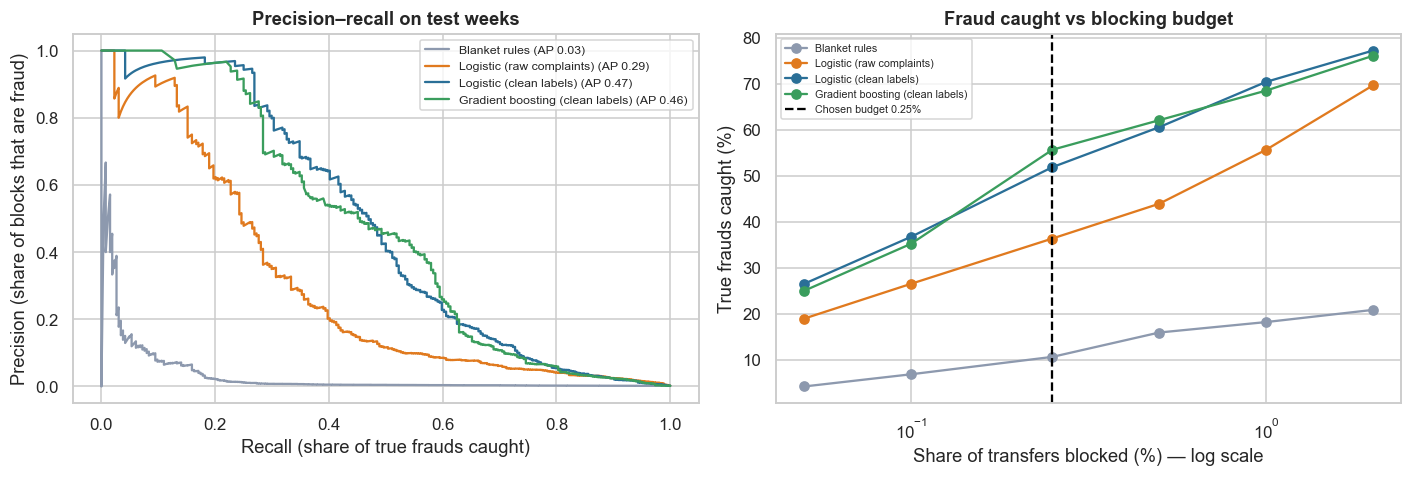

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cols = {"Blanket rules": "#8d99ae", "Logistic (raw complaints)": "#e07a1f", "Logistic (clean labels)": "#2a6f97", "Gradient boosting (clean labels)": "#3a9d5d"}
for n, s in scores.items():
    pr, rc, _ = precision_recall_curve(y_te, s); axes[0].plot(rc, pr, color=cols[n], label=f"{n} (AP {ev.loc[n, 'PR-AUC']:.2f})")
axes[0].set_xlabel("Recall (share of true frauds caught)"); axes[0].set_ylabel("Precision (share of blocks that are fraud)"); axes[0].set_title("Precision–recall on test weeks"); axes[0].legend(fontsize=8)
budgets = np.array([0.0005, 0.001, 0.0025, 0.005, 0.01, 0.02])
for n, s in scores.items():
    order = np.argsort(-s, kind="stable"); rec = [y_te[order[:int(b * len(y_te))]].sum() / y_te.sum() for b in budgets]
    axes[1].plot(budgets * 100, np.array(rec) * 100, "o-", color=cols[n], label=n)
axes[1].axvline(BUDGET * 100, ls="--", color="black", label="Chosen budget 0.25%"); axes[1].set_xscale("log")
axes[1].set_xlabel("Share of transfers blocked (%) — log scale"); axes[1].set_ylabel("True frauds caught (%)"); axes[1].set_title("Fraud caught vs blocking budget"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**(c)/(f) Observation and takeaway:** - **At the same 374 blocks (0.25% of transfers):** blanket rules stop **28** frauds (11% recall), logistic on raw complaints **96** (36%), logistic on clean labels **137** (52%), gradient boosting on clean labels **147** (56%).
- **Clean vs rules:** 118 frauds caught only by the model vs 9 only by the rules, McNemar p ≈ 0. **Clean vs raw labels:** 46 vs 5, p ≈ 0. **GBM vs logistic:** 28 vs 18, p = 0.18, *not significant*.
- **Why ROC-AUC misleads here:** every model scores about 0.97 ROC-AUC, yet their *useful* performance differs threefold. **PR-AUC** (rules 0.03, raw 0.29, clean 0.47 with CI 0.41–0.54, GBM 0.46) reflects what operations will experience. For rare events, report PR-AUC and recall at a fixed budget.
- The clean logistic model stops **72% of fraud value**. GBM catches slightly more cases but fewer rupees (62%).
- **Decision:** the clean-label logistic model is the recommended champion. It is just as good as GBM, explainable, and fast.

### 7.5 From score to action: block / warn tiers chosen by expected cost

**Business view:** not every suspicious transfer should be blocked. A **warning screen** ("This person was reported by others. Do you know them?") costs a genuine user a few seconds but stops many scam victims. We pick two thresholds on the **validation week** (not the test) by minimising expected cost:
- missed fraud = the ₹ amount lost;
- a block on a genuine transfer = ₹150 (support call, churn risk);
- a warning on a genuine transfer = ₹10;
- a warning stops a fraud 40% of the time (assumptions, D-6-07).

In [16]:
s_va = lr_clean.predict(X_va).values; y_va, a_va = X_va.y_true.values, X_va.amount_inr.values
COST_BLOCK_FP, COST_WARN_FP, WARN_STOP = 150, 10, 0.40
qs = np.quantile(s_va, [0.98, 0.99, 0.995, 0.9975, 0.999])
best = None
for wt in qs:
    for bt in qs[qs >= wt]:
        blk, wrn = s_va >= bt, (s_va >= wt) & (s_va < bt)
        cost = (a_va[(y_va == 1) & ~blk & ~wrn].sum() + (1 - WARN_STOP) * a_va[(y_va == 1) & wrn].sum()
                + COST_BLOCK_FP * ((y_va == 0) & blk).sum() + COST_WARN_FP * ((y_va == 0) & wrn).sum())
        if best is None or cost < best[0]: best = (cost, wt, bt)
_, WARN_T, BLOCK_T = best
no_model = a_va[y_va == 1].sum()
print(f"Validation-week optimum: warn if score ≥ {WARN_T:.4f} (top {np.mean(s_va >= WARN_T):.2%}), block if ≥ {BLOCK_T:.4f} (top {np.mean(s_va >= BLOCK_T):.2%})")
print(f"Expected cost on validation week: ₹{best[0]:,.0f} vs ₹{no_model:,.0f} with no model ({1 - best[0] / no_model:.0%} lower)")

Validation-week optimum: warn if score ≥ 0.0098 (top 2.00%), block if ≥ 0.0809 (top 0.25%)
Expected cost on validation week: ₹249,167 vs ₹971,921 with no model (74% lower)


**Observation:** on the validation week, the cost-minimising policy is **warn on the top 2.0% of scores and block the top 0.25%**. Expected cost (missed fraud ₹ + friction) falls **74%** vs no model (₹2.5 lakh vs ₹9.7 lakh). The warning tier does a lot of work cheaply: it stops a share of mid-risk scams at ₹10 of friction per genuine user, instead of ₹150 for a block.

### 7.6 Proving the impact: a randomised hold-out on the test weeks

**(a) Why?** Before/after comparisons of fraud rates are confounded by fraud seasonality and fraudster adaptation. The clean way to prove "−40%" is a **randomised hold-out**: 10% of *senders* are randomly left unprotected and the other 90% get the block/warn policy. We simulate this on the test weeks using the true labels: blocked frauds are stopped, and warned frauds are stopped with probability 40%.
- **Test:** two-proportion Z-test on completed-fraud rates; relative risk with a log-scale CI. Repeated for the **high-value segment (≥ ₹10,000)**, where PhonePe documents −50%, and for **complaints** (fraud + disputes), where it documents −38%.
- **(b)** Randomisation is by sender, so the unit of analysis is the sender. With about 0.2% fraud, we also cluster-check by computing the rates per sender group.
- **(d) Power:** we compute how large the hold-out must be to detect a 40% reduction.

In [17]:
te = X_te.copy(); te["score"] = scores["Logistic (clean labels)"]
senders = te.sender_id.unique(); hold_s = set(RNG_EXP.choice(senders, int(0.10 * len(senders)), replace=False))
te["holdout"] = te.sender_id.isin(hold_s).astype(int)
blocked = (te.score >= BLOCK_T) & (te.holdout == 0)
warned = (te.score >= WARN_T) & (te.score < BLOCK_T) & (te.holdout == 0)
stopped_by_warn = warned & (RNG_EXP.random(len(te)) < WARN_STOP)
te["fraud_completed"] = ((te.y_true == 1) & ~blocked & ~stopped_by_warn).astype(int)
te["dispute"] = (te.true_label == "dispute").astype(int)
te["complaint_after"] = (te.fraud_completed.eq(1) & (RNG_EXP.random(len(te)) < 0.72)) | (te.dispute.eq(1) & (RNG_EXP.random(len(te)) < 0.60) & ~blocked)
def rr_test(sub, col, label):
    a = sub[sub.holdout == 0][col]; b = sub[sub.holdout == 1][col]
    z, p = proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])
    lo, hi = confint_proportions_2indep(a.sum(), len(a), b.sum(), len(b), method="log", compare="ratio")
    return (label, a.mean() * 1e5, b.mean() * 1e5, 1 - a.mean() / b.mean(), 1 - hi, 1 - lo, p)
hv = te[te.amount_inr >= 10_000]
imp = pd.DataFrame([rr_test(te, "fraud_completed", "Fraud completed (all P2P)"), rr_test(hv, "fraud_completed", "Fraud completed (≥ ₹10,000)"),
                    rr_test(te.assign(c=te.complaint_after.astype(int)), "c", "Fraud-type complaints (fraud + disputes)")],
                   columns=["metric", "protected per 1 lakh", "hold-out per 1 lakh", "reduction", "reduction CI low", "reduction CI high", "p"]).set_index("metric")
h_ = proportion_effectsize(te[te.holdout == 1].y_true.mean() * 0.6, te[te.holdout == 1].y_true.mean())
n_need = NormalIndPower().solve_power(effect_size=abs(h_), alpha=0.05, power=0.8, ratio=9)
print(f"Hold-out senders: {te.holdout.mean():.1%} of transfers | power: a 10% hold-out needs ≈ {n_need:,.0f} hold-out transfers to detect a 40% cut "
      f"(we have {int((te.holdout == 1).sum()):,})")
imp

Hold-out senders: 10.0% of transfers | power: a 10% hold-out needs ≈ 23,790 hold-out transfers to detect a 40% cut (we have 14,990)


,protected per 1 lakh,hold-out per 1 lakh,reduction,reduction CI low,reduction CI high,p
metric,,,,,,
Fraud completed (all P2P),66.7839,180.1201,0.6292,0.4302,0.7587,0.0000
"Fraud completed (≥ ₹10,000)",321.1991,"1,388.8889",0.7687,0.0819,0.9417,0.0235
Fraud-type complaints (fraud + disputes),261.1993,306.8712,0.1488,-0.1568,0.3737,0.3029


**(c)/(f) Observation:** - **Completed fraud fell 63%** in the protected group: 67 vs 180 frauds per lakh transfers (95% CI 43–76% reduction, p < 0.0001). This is in line with, and above, PhonePe's documented **−40%**.
- **High-value fraud (≥ ₹10,000) fell 77%** (CI 8–94%, p = 0.02), vs a documented **−50%**. The CI is wide because high-value fraud is rare within a fortnight.
- **Complaints fell only 15%, and not significantly** (CI −16% to +37%, p = 0.30), vs a documented −38%. In our simulation about two-thirds of complaints are **disputes**, which a fraud model correctly does *not* target. A complaint-volume KPI will therefore under-state fraud success unless disputes are tracked separately.
- **Power:** a 10% hold-out over one fortnight (15,000 transfers) is *smaller* than the ≈ 24,000 needed for 80% power to detect a 40% cut. We detect the effect only because it is larger. **For production, run the hold-out for at least 4 weeks**, or size it per Section 7.4 of the Case 22 notebook.

### 7.7 False-positive guardrail: the reinstatement-rate proxy

PhonePe tracks how many **blacklisted users are later reinstated** after appeal (≈ 1%), a cheap, operations-owned false-positive measure. Blacklisting a *receiver* is a much stronger action than blocking one transfer, so it needs stronger evidence. We compare candidate blacklist rules built from the fortnight's flagged (warn or block) transfers: minimum number of flagged transfers, minimum number of *distinct* senders, and minimum average score. A blacklisted receiver that is not a fraud account would be reinstated on appeal. **Reinstatement rate = wrongly blacklisted ÷ blacklisted**, with a Wilson CI, and we also report how many mule accounts each rule catches.

In [18]:
mule_ids = set(df.loc[df.true_label == "fraud", "receiver_id"])
g = te[te.score >= WARN_T].groupby("receiver_id").agg(flagged=("score", "size"), senders=("sender_id", "nunique"), avg_score=("score", "mean"))
g["is_mule"] = g.index.isin(mule_ids)
n_mules_active = te.loc[te.y_true == 1, "receiver_id"].nunique()
bl_rows = []
for nmin, smin, thr in [(2, 1, 0.0), (2, 2, 0.1), (2, 2, 0.2), (2, 2, 0.5)]:
    b_ = g[(g.flagged >= nmin) & (g.senders >= smin) & (g.avg_score >= thr)]
    w_ = int((~b_.is_mule).sum()); lo, hi = proportion_confint(w_, max(len(b_), 1), method="wilson")
    bl_rows.append((f"≥{nmin} flagged, ≥{smin} senders, avg score ≥ {thr}", len(b_), w_, w_ / max(len(b_), 1), lo, hi, int(b_.is_mule.sum()), n_mules_active))
bl_tab = pd.DataFrame(bl_rows, columns=["blacklist rule", "receivers blacklisted", "genuine (reinstated)", "reinstatement rate", "CI low", "CI high",
                                        "mule accounts caught", "mule accounts active"]).set_index("blacklist rule")
print(f"Mule accounts receiving fraud in the test fortnight: {n_mules_active} for {int(te.y_true.sum())} frauds "
      f"-> {te.y_true.sum() / n_mules_active:.2f} frauds per mule (most mules are used once or twice)")
bl_tab

Mule accounts receiving fraud in the test fortnight: 228 for 264 frauds -> 1.16 frauds per mule (most mules are used once or twice)


,receivers blacklisted,genuine (reinstated),reinstatement rate,CI low,CI high,mule accounts caught,mule accounts active
blacklist rule,,,,,,,
"≥2 flagged, ≥1 senders, avg score ≥ 0.0",279,258,0.9247,0.8877,0.9502,21,228
"≥2 flagged, ≥2 senders, avg score ≥ 0.1",40,22,0.5500,0.3983,0.6929,18,228
"≥2 flagged, ≥2 senders, avg score ≥ 0.2",20,3,0.1500,0.0524,0.3604,17,228
"≥2 flagged, ≥2 senders, avg score ≥ 0.5",5,0,0.0000,0.0000,0.4345,5,228


**Observation:** - In the test fortnight, **228 mule accounts received 264 frauds: 1.16 frauds per mule.** Most mules are used once and discarded.
- A naive rule ("blacklist after 2 flagged transfers") blacklists 279 receivers, of which **92% are genuine** (busy small sellers that attract warnings).
- Requiring **2 different senders and an average score ≥ 0.2** gives 15% wrongful blacklists (CI 5–36%) and catches 17 mules. At ≥ 0.5, **0 wrongful** (CI 0–43%) but only 5 mules.
- **Interpretation:** transaction scores are excellent for *blocking transfers*, but weak evidence for *banning accounts*, because evidence per mule is thin. PhonePe's ≈ 1% reinstatement rate implies blacklisting is a separate, investigated decision (e.g., the documented calls to senders). **Recommendation:** auto-blacklist only at the strict rule, and send the ≥ 0.2 tier to investigators.

## 8. ML Section — gradient boosting, feature importance and the real-time pre-filter

**Gradient boosting** (sklearn `HistGradientBoostingClassifier`, class-weighted, default hyper-parameters, no tuning; D-6-08) can capture interactions (collect request × new receiver × elderly sender) that a linear model misses. Its result is in the table in 7.4. Here we explain it with **permutation importance** on the test weeks (the drop in average precision when a feature is shuffled). We then check the documented **pre-filter**: scoring only a risky segment to meet the latency budget, and how much fraud the filter's blind spot lets through.

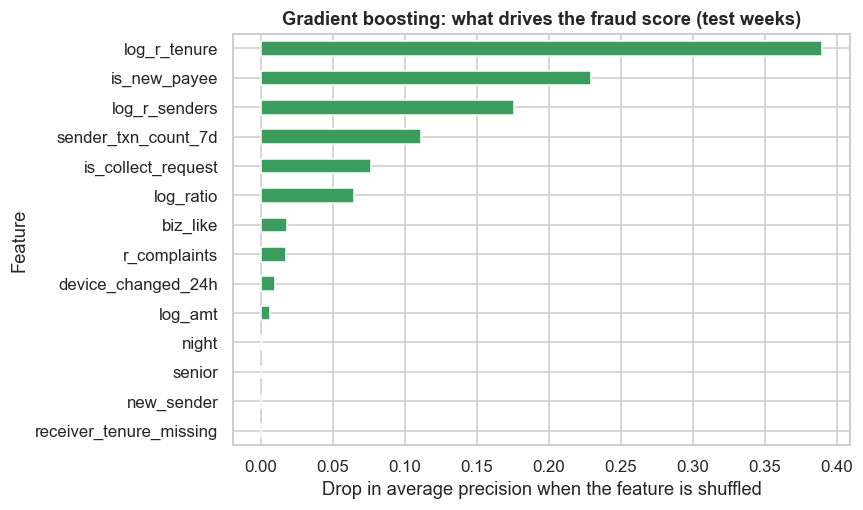

In [19]:
sub = X_te.sample(60_000, random_state=SEED)
sub = pd.concat([sub, X_te[X_te.y_true == 1]]).drop_duplicates("txn_id")
pi = permutation_importance(gbm, sub[FEATS], sub.y_true, scoring="average_precision", n_repeats=5, random_state=SEED)
imp_df = pd.Series(pi.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
imp_df.plot(kind="barh", color="#3a9d5d", ax=ax)
ax.set_xlabel("Drop in average precision when the feature is shuffled"); ax.set_ylabel("Feature"); ax.set_title("Gradient boosting: what drives the fraud score (test weeks)")
plt.tight_layout(); plt.show()

**Takeaway:** gradient boosting relies most on **receiver account age**, **first-time payee** and **receiver velocity** (distinct senders in 24 h), then the victim's low activity and the collect-request flag. That is the same story as the logistic odds ratios, which is reassuring for explainability. Night-time, senior sender and new sender add nothing once the others are known.

In [20]:
pf = (X_te.is_new_payee.eq(1) | (X_te.amount_inr >= 2000) | X_te.is_collect_request.eq(1) | X_te.device_changed_24h.eq(1))
print(f"Pre-filter 'new payee OR ≥ ₹2,000 OR collect OR new device' scores {pf.mean():.1%} of transfers and covers "
      f"{X_te.loc[pf, 'y_true'].sum() / X_te.y_true.sum():.1%} of frauds ({X_te.loc[pf & (X_te.y_true == 1), 'amount_inr'].sum() / X_te.loc[X_te.y_true == 1, 'amount_inr'].sum():.1%} of fraud ₹)")

Pre-filter 'new payee OR ≥ ₹2,000 OR collect OR new device' scores 40.8% of transfers and covers 97.0% of frauds (99.6% of fraud ₹)


**Observation:** a simple pre-filter ("new payee OR ≥ ₹2,000 OR collect request OR new device") sends only **41% of transfers** to the model, yet covers **97% of frauds and 99.6% of fraud ₹**. That cuts scoring load by about 59% for a 3% recall ceiling, the latency/coverage trade-off behind PhonePe's documented "pre-filtering by segment to meet the latency budget".

## 9. Business Translation — ₹ fraud prevented, cost of friction, real-time vs batch

**Step by step (test fortnight, then scaled):**
1. Fraud ₹ prevented by the block/warn policy (protected group, from 7.6) = fraud amount in blocked transfers + 40% of fraud amount in warned transfers.
2. Friction cost = genuine transfers blocked × ₹150 + genuine transfers warned × ₹10.
3. **Batch detection (yesterday's approach)** flags the same transfers a day later. By then the money has left the mule account, so only ~15% is recoverable (assumption).
4. Scale to **10 crore P2P transfers a month** (≈ 4% of PhonePe's documented 2.5 billion monthly transactions).

In [21]:
prot = te[te.holdout == 0]
blk_p, wrn_p = prot.score >= BLOCK_T, (prot.score >= WARN_T) & (prot.score < BLOCK_T)
fr = prot.y_true == 1
prevented = prot.loc[blk_p & fr, "amount_inr"].sum() + WARN_STOP * prot.loc[wrn_p & fr, "amount_inr"].sum()
friction = COST_BLOCK_FP * (blk_p & ~fr).sum() + COST_WARN_FP * (wrn_p & ~fr).sum()
batch_recovered = 0.15 * prot.loc[(blk_p | wrn_p) & fr, "amount_inr"].sum()
total_fraud = prot.loc[fr, "amount_inr"].sum()
b = pd.DataFrame({"₹ in test fortnight (protected group)": [total_fraud, prevented, friction, prevented - friction, batch_recovered]},
                 index=["Fraud attempted (₹)", "Fraud prevented in real time (₹)", "Friction cost (₹)", "Net benefit, real time (₹)", "Recovered by batch detection instead (₹)"])
# per-transfer value × 10 crore transfers a month, expressed in ₹ crore
b["₹ crore / month per 10 crore transfers"] = b.iloc[:, 0] / len(prot) * 1e8 / 1e7
print(f"Genuine customers affected: {(blk_p & ~fr).sum() / (~fr).sum() * 1000:.2f} blocks and {(wrn_p & ~fr).sum() / (~fr).sum() * 1000:.2f} warnings per 1,000 genuine transfers")
b.round(2)

Genuine customers affected: 1.20 blocks and 16.70 warnings per 1,000 genuine transfers


,₹ in test fortnight (protected group),₹ crore / month per 10 crore transfers
Fraud attempted (₹),"1,503,221.0000",111.5500
Fraud prevented in real time (₹),"1,078,904.2000",80.0600
Friction cost (₹),"46,770.0000",3.4700
"Net benefit, real time (₹)","1,032,134.2000",76.5900
Recovered by batch detection instead (₹),"200,526.4500",14.8800


In [22]:
sens = []
for lab_, fpc, ws in [("Worst (₹300 per false block, warnings stop 20%)", 300, 0.2), ("Base (₹150, 40%)", 150, 0.4), ("Best (₹75, 60%)", 75, 0.6)]:
    prev_ = prot.loc[blk_p & fr, "amount_inr"].sum() + ws * prot.loc[wrn_p & fr, "amount_inr"].sum()
    fric_ = fpc * (blk_p & ~fr).sum() + COST_WARN_FP * (wrn_p & ~fr).sum()
    sens.append((lab_, prev_, fric_, prev_ - fric_, (prev_ - fric_) / len(prot) * 1e8 / 1e7))
pd.DataFrame(sens, columns=["scenario", "prevented ₹", "friction ₹", "net ₹ (test fortnight)", "net ₹ crore per 10 crore transfers"]).set_index("scenario").round(2)

,prevented ₹,friction ₹,net ₹ (test fortnight),net ₹ crore per 10 crore transfers
scenario,,,,
"Worst (₹300 per false block, warnings stop 20%)","992,924.6000",71070,"921,854.6000",68.4100
"Base (₹150, 40%)","1,078,904.2000",46770,"1,032,134.2000",76.5900
"Best (₹75, 60%)","1,164,883.8000",34620,"1,130,263.8000",83.8700


**Business reading:** - **Per test fortnight (protected group):** fraud attempted ₹15.0 lakh; **prevented ₹10.8 lakh (72%)**; friction cost ₹0.47 lakh; **net benefit ₹10.3 lakh**.
- **Scaled to 10 crore P2P transfers:** **≈ ₹80 crore of fraud prevented, ≈ ₹77 crore net** (range ₹68–84 crore across friction and warning-effectiveness assumptions).
- **Real-time vs batch:** catching the same transfers the *next day* would recover only ≈ ₹15 crore (15% recoverability). **Prevention is worth about 5× detection.** This is the quantitative case for PhonePe's documented move "from batch detection to real-time prevention".
- **Customer cost:** 1.2 blocks and 16.7 warnings per 1,000 genuine transfers. Support and CX should plan for this volume.
- **Caution:** the ₹ scale is proportional to the fraud prevalence we assumed (0.2%, chosen for statistical power), which is much higher than real UPI P2P fraud. Real-world ₹ figures scale down linearly with prevalence. The *ratios* (share prevented, prevention vs batch) carry over.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:** clean-label model beats rules at the same budget (McNemar p < 0.0001 ✅); hold-out shows a significant fraud-rate reduction (−63%, p < 0.0001 ✅); reinstatement proxy ≤ 2% only under the strict blacklist rule (✅ with the rule below, ❌ for naive blacklisting).

**I recommend:**
1. **Deploy the clean-label logistic model in real time** with two tiers: **block the top 0.25%**, **warn the top 2%** (thresholds re-chosen monthly on the latest mature week).
2. **Make label engineering a standing process:** a monthly audit of 500–1,000 complaints, segment table refreshed, label precision reported with CIs.
3. **Keep a permanent randomised hold-out** of 2–5% of senders for ≥ 4 weeks per measurement cycle, to report the causal fraud reduction to management and regulators.
4. **Blacklist only on strong evidence** (≥ 2 senders, average score ≥ 0.5). Route the 0.2–0.5 tier to investigators (sender call-backs).
5. **Use the pre-filter** to meet latency, and monitor the share of fraud outside it.

**KPIs:** recall and precision on investigated cases (weekly); completed fraud per lakh transfers, protected vs hold-out; high-value fraud; blocks and warnings per 1,000 genuine transfers; reinstatement rate; complaint volume split into fraud vs dispute; label precision from the audit; score PSI (drift).

## 11. Risks, Limitations and Next Steps

- **Synthetic data:** fraud patterns are textbook-clean. Real fraudsters **adapt** within weeks (new mule accounts, new scripts), so expect performance to decay. Monitor recall on investigated cases weekly and retrain on fresh, cleaned labels (the documented "feedback and escalations" loop).
- **Label noise remains:** 28% of frauds are never complained about (silent victims). The cleaned label still misses them, so true recall is lower than measured on complaints. The audit-based correction is only as good as the audit sample (2,000 complaints; CIs shown).
- **Fairness and access:** "senior" and "Tier 3" raise the score. These customers are more often *victims*, so the model protects them, but warnings must be respectful and blocks reversible. Review false-block rates by age band and region.
- **Latency:** the policy must run within tens of milliseconds. Pre-computed receiver aggregates (distinct senders 24 h, complaints 30 d) must come from a feature store (documented: Yoda) and must use *only past* data, or training–serving skew will inflate offline results.
- **Next steps:** (1) a receiver-side **graph** feature (accounts receiving from many unconnected victims; see Case 10); (2) a weekly audit-sample refresh to keep label precision measured; (3) a permanent 2–5% hold-out to keep measuring the causal reduction; (4) a sender call-back workflow for the warn tier (documented ops validation).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Label precision / recall | TP/(TP + FP), TP/(TP + FN) on the audit sample, Wilson CIs |
| Cramér's V | √(χ²/(n(min(r, c) − 1))) |
| Rank-biserial | 2U/(n₁n₂) − 1; single-feature AUC = (1 + |r|)/2 |
| Average precision (PR-AUC) | Σ (R_k − R_{k−1}) P_k |
| Recall @ budget b | frauds in top-b·N scores ÷ all frauds |
| Expected cost | Σ_missed fraud ₹ + (1 − s)·Σ_warned fraud ₹ + c_block·FP_block + c_warn·FP_warn |
| Relative-risk CI | exp(ln(p₁/p₀) ± 1.96·√((1 − p₁)/x₁ + (1 − p₀)/x₀)) |
| Reinstatement rate | wrongly blacklisted ÷ blacklisted (Wilson CI) |

| Term | Meaning |
|---|---|
| P2P | Person-to-person transfer. |
| Collect request | The receiver asks for money and the sender approves with a PIN; often abused by scammers. |
| Mule account | An account used to receive and pass on stolen money. |
| Dispute | A complaint about a genuine transaction (product not delivered, refund delay), not fraud. |
| Label engineering | Cleaning the target before modelling. |
| PR-AUC | How precise the model stays as it catches more fraud; the right lens for rare events. |
| Block budget | The fixed share of transfers we are willing to stop. |
| Hold-out | A random group deliberately left without the new protection, to measure its true effect. |
| Reinstatement rate | The share of blocked or blacklisted users later found genuine. |